#  Sunrise Supermarket — Full AI Data Pipeline
### Data Cleaning → EDA → Feature Engineering → Model Training
---

##  Step 0 — Install Libraries
Run this once only.

In [22]:
!pip install pandas numpy scikit-learn mlxtend matplotlib seaborn

'pip' is not recognized as an internal or external command,
operable program or batch file.


##  Step 1 — Imports & Setup

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

print("All libraries imported!")

All libraries imported!


---
## Step 2 — Load Data

In [24]:
txns   = pd.read_csv('transactions.csv')
items  = pd.read_csv('transaction_items.csv')
custs  = pd.read_csv('customers.csv')
catalog= pd.read_csv('product_catalog_rows.csv')

print(f"transactions:      {txns.shape}")
print(f"transaction_items: {items.shape}")
print(f"customers:             {custs.shape}")
print(f"product_catalog:       {catalog.shape}")

transactions:      (1227, 4)
transaction_items: (6104, 5)
customers:             (150, 25)
product_catalog:       (112, 8)


---
## Step 3 — Exploratory Data Analysis (EDA)

In [25]:
print("=== OVERVIEW ===")
print(f"Total transactions:    {len(txns)}")
print(f"Total customers:       {txns['customer_id'].nunique()}")
print(f"Total products tracked:{items['product_code'].nunique()}")
print(f"Avg transaction value: LKR {txns['total_amount'].mean():.2f}")
print(f"Max transaction value: LKR {txns['total_amount'].max():.2f}")

=== OVERVIEW ===
Total transactions:    1227
Total customers:       150
Total products tracked:112
Avg transaction value: LKR 4154.33
Max transaction value: LKR 14971.63


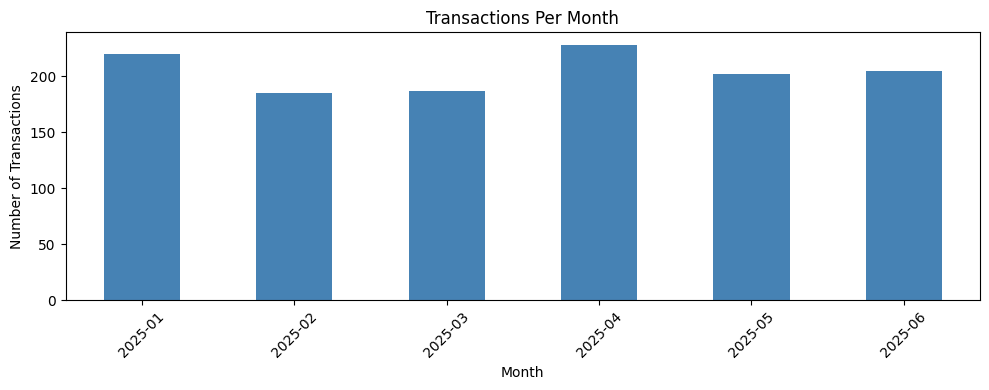

month
2025-01    220
2025-02    185
2025-03    187
2025-04    228
2025-05    202
2025-06    205
Freq: M


In [26]:
# Transactions per month
# Ensure datetime type even if cleaning cells were not run yet
txns['transaction_date'] = pd.to_datetime(txns['transaction_date'], errors='coerce')
monthly = txns.dropna(subset=['transaction_date']).copy()
monthly['month'] = monthly['transaction_date'].dt.to_period('M')
monthly = monthly.groupby('month').size()

plt.figure(figsize=(10, 4))
monthly.plot(kind='bar', color='steelblue')
plt.title('Transactions Per Month')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(monthly.to_string())

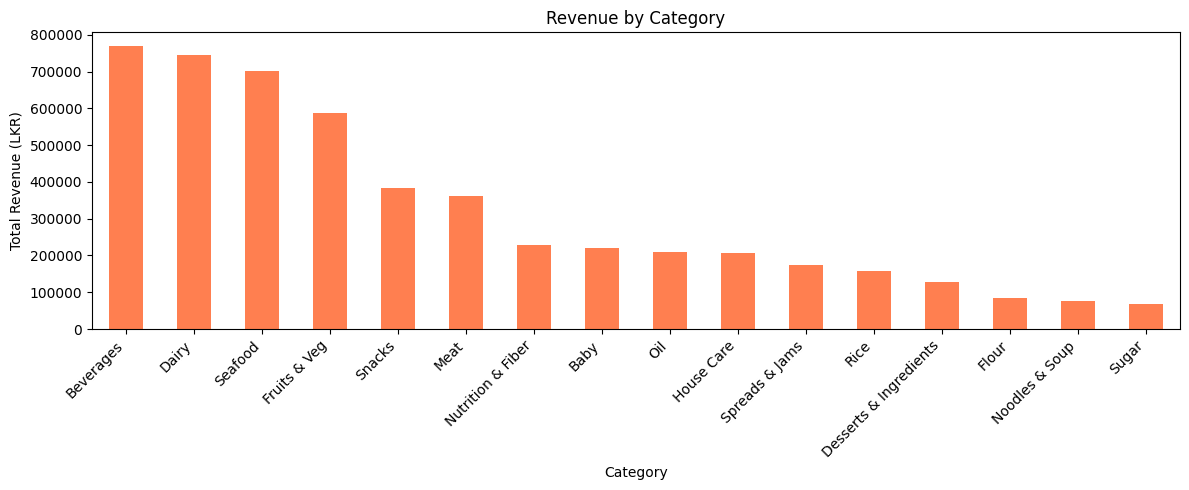

category
Beverages                 768609.84641
Dairy                     745412.73042
Seafood                   701993.27660
Fruits & Veg              587021.33831
Snacks                    384301.14136
Meat                      360911.19698
Nutrition & Fiber         227556.25886
Baby                      220172.24446
Oil                       209158.55000
House Care                206881.04321
Spreads & Jams            173493.83968
Rice                      157260.16500
Desserts & Ingredients    126616.44935
Flour                      83908.65500
Noodles & Soup             75143.75955
Sugar                      68920.63500


In [27]:
# Revenue by category
merged = items.merge(catalog[['product_code','category']], on='product_code', how='left')
merged['line_total'] = merged['quantity'] * merged['unit_price']

cat_revenue = merged.groupby('category')['line_total'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
cat_revenue.plot(kind='bar', color='coral')
plt.title('Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue (LKR)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
print(cat_revenue.to_string())

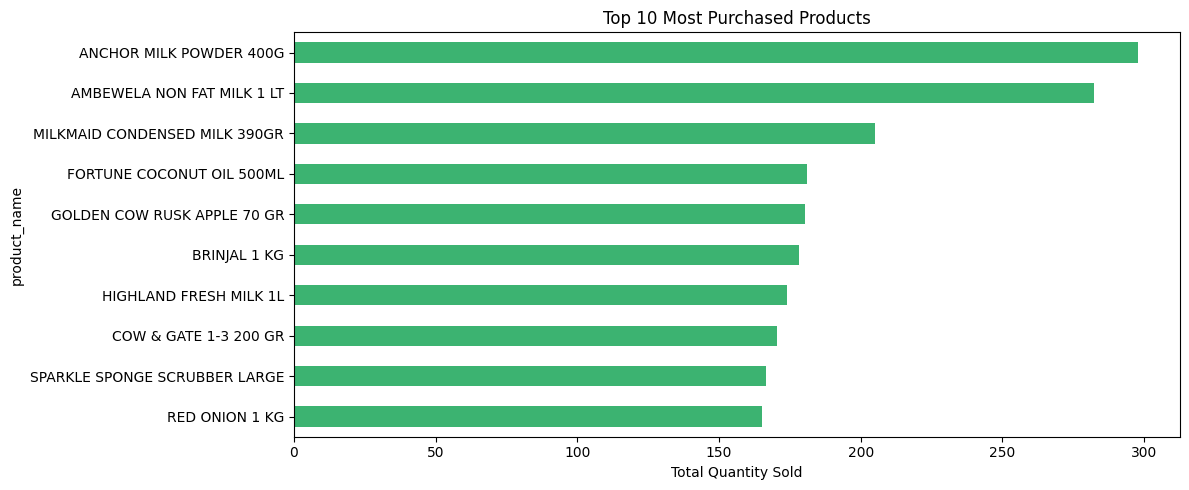

In [28]:
# Top 10 most purchased products
merged2 = items.merge(catalog[['product_code','product_name']], on='product_code', how='left')
top_products = (merged2.groupby('product_name')['quantity']
                .sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(12, 5))
top_products.plot(kind='barh', color='mediumseagreen')
plt.title('Top 10 Most Purchased Products')
plt.xlabel('Total Quantity Sold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

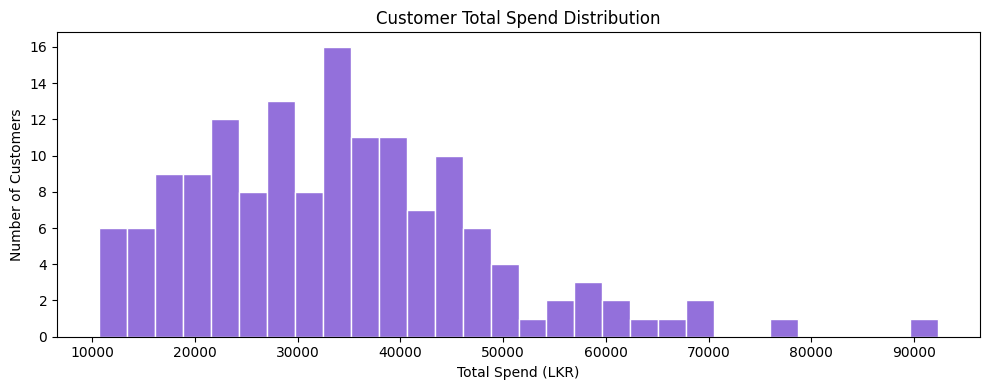

Avg customer spend: LKR 33982.41
Max customer spend: LKR 92339.28
Min customer spend: LKR 10657.33


In [29]:
# Customer spend distribution
cust_spend = txns.groupby('customer_id')['total_amount'].sum()

plt.figure(figsize=(10, 4))
plt.hist(cust_spend, bins=30, color='mediumpurple', edgecolor='white')
plt.title('Customer Total Spend Distribution')
plt.xlabel('Total Spend (LKR)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print(f"Avg customer spend: LKR {cust_spend.mean():.2f}")
print(f"Max customer spend: LKR {cust_spend.max():.2f}")
print(f"Min customer spend: LKR {cust_spend.min():.2f}")

---
## Step 4 — Feature Engineering for K-Means
### Combined RFM + Taste Profile

In [30]:
merged = items.merge(catalog[['product_code','category']], on='product_code', how='left')
merged = merged.merge(txns[['transaction_id','customer_id','transaction_date']], on='transaction_id', how='left')
merged['line_total'] = merged['quantity'] * merged['unit_price']
today = pd.Timestamp('2025-07-01')

# RFM features
total_spent     = merged.groupby('customer_id')['line_total'].sum().reset_index(name='total_spent')
txn_count       = txns.groupby('customer_id').size().reset_index(name='transaction_count')
avg_basket      = txns.groupby('customer_id')['total_amount'].mean().reset_index(name='avg_basket_value')
last_purchase   = txns.groupby('customer_id')['transaction_date'].max().reset_index()
last_purchase['days_since_last_purchase'] = (today - pd.to_datetime(last_purchase['transaction_date'])).dt.days
last_purchase   = last_purchase[['customer_id','days_since_last_purchase']]

# Taste profile features - % spend per category
cat_spend = merged.groupby(['customer_id','category'])['line_total'].sum().unstack(fill_value=0)
cat_pct   = cat_spend.div(cat_spend.sum(axis=1), axis=0) * 100
cat_pct.columns = [f"pct_{c.lower().replace(' ','_').replace('&','and')}" for c in cat_pct.columns]
cat_pct   = cat_pct.reset_index()

# Combine all
kmeans_df = (custs[['customer_id']]
             .merge(total_spent,   on='customer_id', how='left')
             .merge(txn_count,     on='customer_id', how='left')
             .merge(avg_basket,    on='customer_id', how='left')
             .merge(last_purchase, on='customer_id', how='left')
             .merge(cat_pct,       on='customer_id', how='left')
             .fillna(0))

print(f"K-Means feature matrix shape: {kmeans_df.shape}")
print(f"\nFeatures:")
for col in kmeans_df.columns[1:]:
    print(f"  {col}")
kmeans_df.head()

K-Means feature matrix shape: (150, 21)

Features:
  total_spent
  transaction_count
  avg_basket_value
  days_since_last_purchase
  pct_baby
  pct_beverages
  pct_dairy
  pct_desserts_and_ingredients
  pct_flour
  pct_fruits_and_veg
  pct_house_care
  pct_meat
  pct_noodles_and_soup
  pct_nutrition_and_fiber
  pct_oil
  pct_rice
  pct_seafood
  pct_snacks
  pct_spreads_and_jams
  pct_sugar


,customer_id,total_spent,transaction_count,avg_basket_value,days_since_last_purchase,pct_baby,pct_beverages,pct_dairy,pct_desserts_and_ingredients,pct_flour,...,pct_house_care,pct_meat,pct_noodles_and_soup,pct_nutrition_and_fiber,pct_oil,pct_rice,pct_seafood,pct_snacks,pct_spreads_and_jams,pct_sugar
0,CUST0001,12842.70224,6,2140.45000,15,0.000000,5.476106,0.000000,0.000000,12.232472,...,2.020463,0.000000,0.000000,0.681861,9.552312,0.000000,0.000000,39.861538,0.000000,3.212603
1,CUST0002,43964.78580,10,4396.47800,45,15.144604,0.000000,39.682874,3.651485,0.000000,...,0.000000,0.000000,0.922788,0.000000,3.763830,0.000000,4.389513,2.109580,25.476108,1.399290
2,CUST0003,10657.32236,5,2131.46600,39,0.000000,29.868018,7.632499,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.762276,0.000000,0.000000,15.322798,33.081945,9.934237,0.000000
3,CUST0004,45851.47716,7,6550.21000,64,0.000000,31.438053,5.814625,0.000000,2.070217,...,0.000000,6.404679,0.243437,17.008621,0.000000,1.135569,2.684755,14.576145,0.000000,0.000000
4,CUST0005,44937.50391,8,5617.18875,14,9.442314,12.915460,27.513664,0.000000,0.000000,...,0.000000,8.311988,0.490540,0.000000,4.403449,3.392267,22.517320,0.000000,0.000000,1.102398


In [31]:
kmeans_df.to_csv('kmeans_features.csv', index=False)
print("✅ kmeans_features.csv saved!")

✅ kmeans_features.csv saved!


---
##  Step 5 — Find Best Number of Clusters (Elbow Method)

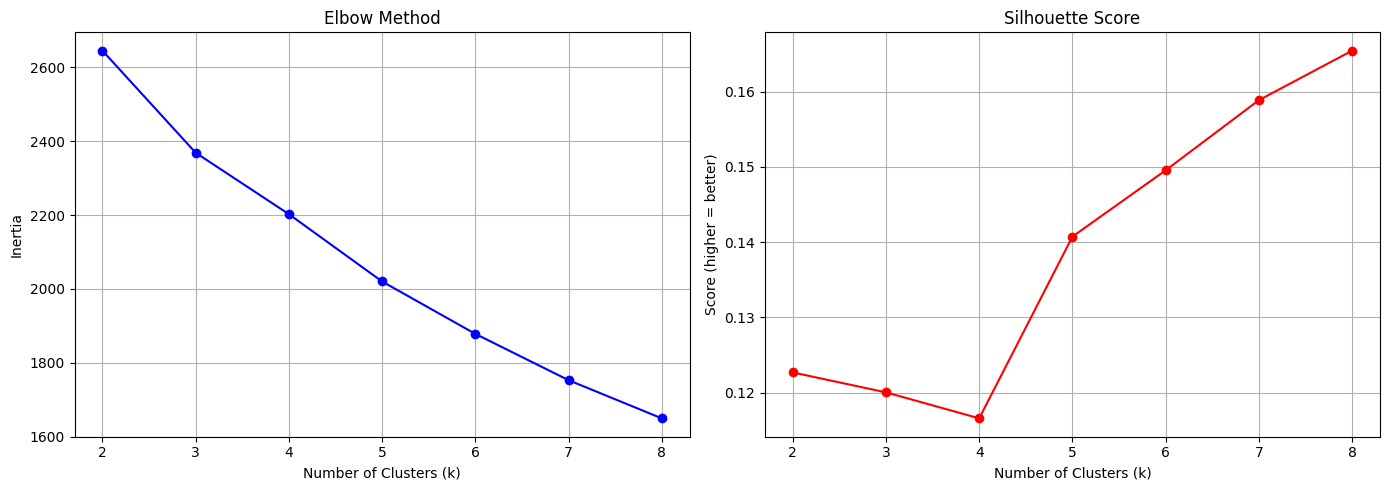

Best k by silhouette score: 8
Recommended: use k=4 for meaningful business segments


In [32]:
feature_cols = [c for c in kmeans_df.columns if c != 'customer_id']
X = kmeans_df[feature_cols].values

# Normalize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method
inertias    = []
silhouettes = []
K_range     = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inertias, 'bo-')
ax1.set_title('Elbow Method')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.grid(True)

ax2.plot(K_range, silhouettes, 'ro-')
ax2.set_title('Silhouette Score')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Score (higher = better)')
ax2.grid(True)

plt.tight_layout()
plt.show()

best_k = K_range[silhouettes.index(max(silhouettes))]
print(f"Best k by silhouette score: {best_k}")
print(f"Recommended: use k=4 for meaningful business segments")

---
##  Step 6 — K-Means Clustering

In [33]:
K = 4  # Change this if elbow suggests different

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_df['cluster'] = kmeans.fit_predict(X_scaled)

print(f"K-Means completed with k={K}")
print(f"\nCluster distribution:")
print(kmeans_df['cluster'].value_counts().sort_index().to_string())

K-Means completed with k=4

Cluster distribution:
cluster
0    34
1    59
2    28
3    29


In [34]:
# Analyze each cluster
cluster_summary = kmeans_df.groupby('cluster').agg(
    customer_count    =('customer_id','count'),
    avg_total_spent   =('total_spent','mean'),
    avg_txn_count     =('transaction_count','mean'),
    avg_basket_value  =('avg_basket_value','mean'),
    avg_days_since    =('days_since_last_purchase','mean')
).round(2)

print("=== CLUSTER PROFILES ===")
print(cluster_summary.to_string())

=== CLUSTER PROFILES ===
         customer_count  avg_total_spent  avg_txn_count  avg_basket_value  avg_days_since
cluster                                                                                  
0                    34         39251.88           7.44           5261.07           28.62
1                    59         25048.32           8.20           3032.32           19.25
2                    28         38347.24           8.21           4676.91           24.29
3                    29         41766.34           8.97           4759.05           16.83


In [35]:
# Find top taste category per cluster
taste_cols = [c for c in kmeans_df.columns if c.startswith('pct_')]
cluster_taste = kmeans_df.groupby('cluster')[taste_cols].mean().round(2)

print("=== TOP TASTE CATEGORIES PER CLUSTER ===")
for cluster in range(K):
    top_cat = cluster_taste.loc[cluster].sort_values(ascending=False).head(3)
    print(f"\nCluster {cluster}:")
    for cat, val in top_cat.items():
        print(f"  {cat.replace('pct_','')}: {val:.1f}%")

=== TOP TASTE CATEGORIES PER CLUSTER ===

Cluster 0:
  seafood: 36.4%
  meat: 18.5%
  fruits_and_veg: 9.2%

Cluster 1:
  fruits_and_veg: 18.8%
  snacks: 16.4%
  beverages: 9.0%

Cluster 2:
  dairy: 34.6%
  baby: 17.3%
  beverages: 9.1%

Cluster 3:
  beverages: 35.4%
  dairy: 17.7%
  nutrition_and_fiber: 10.5%


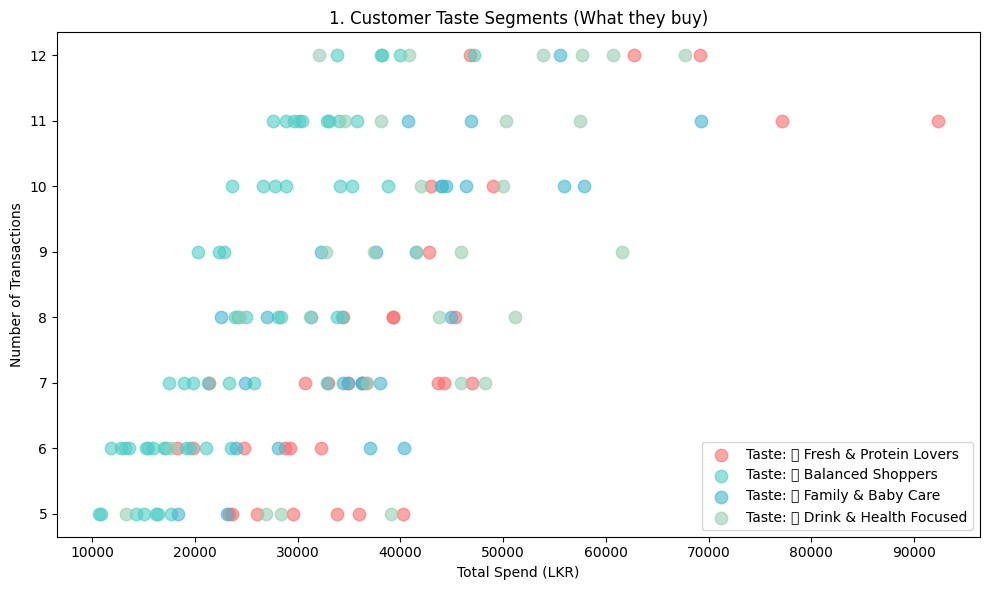

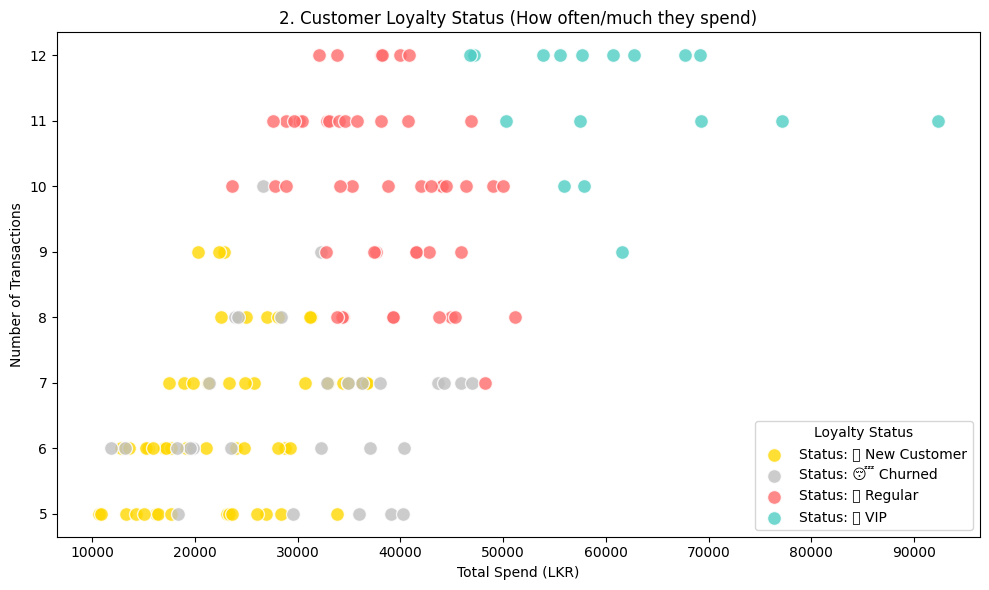

--- Final Segmentation Summary ---
segment_name    🐟 Fresh & Protein Lovers  👶 Family & Baby Care  \
loyalty_status                                                   
🌱 New Customer                        12                     9   
💎 VIP                                  5                     4   
😴 Churned                             10                     7   
🛒 Regular                              7                     8   

segment_name    🥤 Drink & Health Focused  🥦 Balanced Shoppers  
loyalty_status                                                 
🌱 New Customer                         7                   27  
💎 VIP                                  7                    1  
😴 Churned                              2                    9  
🛒 Regular                             13                   22  


In [36]:
# ==========================================
# PART 1: TASTE CLUSTERING (What they buy)
# ==========================================

# 1. Label clusters with business names (Taste)
segment_labels = {
    0: '🐟 Fresh & Protein Lovers',
    1: '🥦 Balanced Shoppers',
    2: '👶 Family & Baby Care',
    3: '🥤 Drink & Health Focused'
}

# 'cluster' comes from your first KMeans run on product percentages
kmeans_df['segment_name'] = kmeans_df['cluster'].map(segment_labels)

# Plot Taste Clusters
plt.figure(figsize=(10, 6))
colors_taste = ['#FF6B6B','#4ECDC4','#45B7D1','#96CEB4']
for i, (cluster, label) in enumerate(segment_labels.items()):
    mask = kmeans_df['cluster'] == cluster
    plt.scatter(
        kmeans_df.loc[mask, 'total_spent'],
        kmeans_df.loc[mask, 'transaction_count'],
        c=colors_taste[i], label=f"Taste: {label}",
        alpha=0.6, s=80
    )

plt.title('1. Customer Taste Segments (What they buy)')
plt.xlabel('Total Spend (LKR)')
plt.ylabel('Number of Transactions')
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# PART 2: LOYALTY CLUSTERING (How they buy)
# ==========================================

# IMPORTANT: We run a second KMeans just for RFM (Loyalty)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

rfm_cols = ['total_spent', 'transaction_count', 'days_since_last_purchase']
scaler_rfm = StandardScaler()
rfm_scaled = scaler_rfm.fit_transform(kmeans_df[rfm_cols])

# Create the loyalty clusters
kmeans_loyalty = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_df['loyalty_cluster'] = kmeans_loyalty.fit_predict(rfm_scaled)

# Define the Logic for Loyalty Labels
rfm_summary = kmeans_df.groupby('loyalty_cluster')[rfm_cols].mean()

def get_loyalty_label(cluster_id):
    if cluster_id == rfm_summary['total_spent'].idxmax():
        return "💎 VIP"
    elif cluster_id == rfm_summary['days_since_last_purchase'].idxmax():
        return "😴 Churned"
    elif cluster_id == rfm_summary['transaction_count'].idxmin():
        return "🌱 New Customer"
    else:
        return "🛒 Regular"

kmeans_df['loyalty_status'] = kmeans_df['loyalty_cluster'].apply(get_loyalty_label)

# Plot Loyalty Clusters
plt.figure(figsize=(10, 6))
colors_loyalty = ['#FFD700', '#C0C0C0', '#FF6B6B', '#4ECDC4'] # Gold, Silver, Red, Teal
loyalty_names = kmeans_df.groupby('loyalty_cluster')['loyalty_status'].first().to_dict()

for i, cluster in enumerate(sorted(kmeans_df['loyalty_cluster'].unique())):
    mask = kmeans_df['loyalty_cluster'] == cluster
    plt.scatter(
        kmeans_df.loc[mask, 'total_spent'], 
        kmeans_df.loc[mask, 'transaction_count'], 
        c=colors_loyalty[i % len(colors_loyalty)], 
        label=f"Status: {loyalty_names[cluster]}",
        alpha=0.8, s=100, edgecolors='white'
    )

plt.title('2. Customer Loyalty Status (How often/much they spend)')
plt.xlabel('Total Spend (LKR)')
plt.ylabel('Number of Transactions')
plt.legend(title="Loyalty Status")
plt.tight_layout()
plt.show()

# Final Summary Table
print("--- Final Segmentation Summary ---")
print(kmeans_df.groupby(['loyalty_status', 'segment_name']).size().unstack(fill_value=0))

In [ ]:
from datetime import date

# 1. Add today's date to every row (Format: YYYY-MM-DD)
kmeans_df['assigned_date'] = date.today().strftime('%Y-%m-%d')

# 2. Map the pipeline's loyalty labels to Supabase segment IDs
segment_id_map = {
    'VIP': 1,
    'Regular': 3,
    'New Customer': 6,
    'Churned': 7
}

# 3. Build the export with the exact Supabase assignment schema
cluster_output = kmeans_df[['customer_id', 'loyalty_status', 'segment_name', 'total_spent', 'transaction_count', 'assigned_date']].copy()
cluster_output['segment_id'] = cluster_output['loyalty_status'].map(segment_id_map)

# 4. Keep only the columns needed by customer_segment_assignment
cluster_output = cluster_output[['customer_id', 'segment_id', 'assigned_date', 'segment_name', 'total_spent', 'transaction_count']]
cluster_output = cluster_output.rename(columns={'segment_name': 'product_preference'})

# 5. Save the Supabase-ready file
cluster_output.to_csv('customer_clusters.csv', index=False)

print("✅ Updated customer_clusters.csv saved!")
print("→ This file now matches customer_segment_assignment.")
print("→ Columns: customer_id, segment_id, assigned_date, product_preference, total_spent, transaction_count")

✅ Updated customer_clusters.csv saved!
→ This file now matches customer_segment_assignment.
→ Columns: customer_id, segment_id, assigned_date, product_preference, total_spent, transaction_count


---
## Step 7 — Apriori Product Recommendation

In [38]:
# Build basket format — list of products per transaction
basket_sets = items.groupby('transaction_id')['product_code'].apply(list).tolist()

# Encode
te = TransactionEncoder()
te_array = te.fit_transform(basket_sets)
basket_df = pd.DataFrame(te_array, columns=te.columns_)

print(f"Basket matrix shape: {basket_df.shape}")
print(f"Transactions: {len(basket_df)}")
print(f"Products: {len(basket_df.columns)}")

Basket matrix shape: (1227, 112)
Transactions: 1227
Products: 112


In [39]:
# Run Apriori
frequent_itemsets = apriori(
    basket_df,
    min_support=0.02,      # lower support to surface more useful rules
    use_colnames=True
)
frequent_itemsets = frequent_itemsets.sort_values('support', ascending=False)

print(f"Frequent itemsets found: {len(frequent_itemsets)}")
print("\nTop 10 most frequent:")
print(frequent_itemsets.head(10).to_string(index=False))

Frequent itemsets found: 148

Top 10 most frequent:
 support  itemsets
0.125509  (DAI092)
0.113284 (BE10004)
0.083945 (BE20004)
0.073350 (BI10018)
0.072535 (VG20012)
0.071720 (BI10046)
0.070905  (OIL032)
0.069275 (DV00004)
0.068460  (DAI101)
0.067645 (DV00005)


In [40]:
# Generate association rules
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.20     # lower confidence to find more cross-sell ideas
)
rules = rules[(rules['lift'] >= 1.1) & (rules['support'] >= 0.01)]
rules['antecedent_len'] = rules['antecedents'].apply(len)
rules['consequent_len'] = rules['consequents'].apply(len)
rules = rules[(rules['antecedent_len'] == 1) & (rules['consequent_len'] == 1)]
rules['rule_key'] = rules.apply(lambda row: tuple(sorted([list(row['antecedents'])[0], list(row['consequents'])[0]])), axis=1)
rules = rules.drop_duplicates('rule_key')
rules = rules.sort_values(['lift', 'confidence', 'support'], ascending=False)

print(f"Association rules found: {len(rules)}")
print("\nTop 15 rules by lift:")
display_cols = ['antecedents','consequents','support','confidence','lift']
print(rules[display_cols].head(15).to_string(index=False))

Association rules found: 31

Top 15 rules by lift:
antecedents consequents  support  confidence     lift
  (HC20093)   (HC30095) 0.032600    0.547945 9.337900
  (HC20093)   (HC20051) 0.030155    0.506849 9.282151
  (HC20051)   (HC30095) 0.028525    0.522388 8.902363
  (BI10018)   (BI10046) 0.044825    0.611111 8.520833
  (HC20069)   (HC20051) 0.026895    0.464789 8.511877
  (HC20069)   (HC20093) 0.028525    0.492958 8.285742
  (HC20069)   (HC30099) 0.027710    0.478873 8.275739
  (HC30075)   (HC30095) 0.031785    0.481481 8.205247
  (BE20004)   (BI10046) 0.048900    0.582524 8.122242
  (HC20069)   (HC30075) 0.030970    0.535211 8.107460
  (HC30075)   (HC30099) 0.030970    0.469136 8.107460
  (HC20093)   (HC30099) 0.026895    0.452055 7.812271
  (HC20051)   (HC30099) 0.024450    0.447761 7.738070
  (HC20051)   (HC30075) 0.027710    0.507463 7.687120
  (HC20069)   (HC30095) 0.026080    0.450704 7.680751


In [41]:
# Category-level rules are usually more useful than exact product pairs
category_baskets = (items.merge(catalog[['product_code', 'category']], on='product_code', how='left')
                   .groupby('transaction_id')['category']
                   .apply(lambda x: sorted(set(x.dropna())))
                   .tolist())

category_te = TransactionEncoder()
category_array = category_te.fit_transform(category_baskets)
category_df = pd.DataFrame(category_array, columns=category_te.columns_)

category_itemsets = apriori(category_df, min_support=0.08, use_colnames=True)
category_rules = association_rules(category_itemsets, metric='confidence', min_threshold=0.25)
category_rules = category_rules[(category_rules['lift'] >= 1.1) & (category_rules['support'] >= 0.03)]
category_rules = category_rules.sort_values(['lift', 'confidence', 'support'], ascending=False)

print(f"Category rules found: {len(category_rules)}")
print("\nTop 10 category rules:")
print(category_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).to_string(index=False))

Category rules found: 7

Top 10 category rules:
        antecedents consequents  support  confidence     lift
             (Baby)     (Dairy) 0.083945    0.837398 2.870078
            (Dairy)      (Baby) 0.083945    0.287709 2.870078
        (Beverages)    (Snacks) 0.134474    0.417722 1.167527
           (Snacks) (Beverages) 0.134474    0.375854 1.167527
            (Dairy) (Beverages) 0.106764    0.365922 1.136674
        (Beverages)     (Dairy) 0.106764    0.331646 1.136674
(Nutrition & Fiber)    (Snacks) 0.080685    0.399194 1.115741


In [42]:
# Add product names to rules for readability
def get_name(codes):
    names = []
    for code in codes:
        name = catalog.set_index('product_code')['product_name'].get(code, code)
        names.append(name)
    return ', '.join(names)

rules['antecedent_name'] = rules['antecedents'].apply(get_name)
rules['consequent_name'] = rules['consequents'].apply(get_name)

print("=== TOP PRODUCT RECOMMENDATIONS ===")
for _, row in rules.head(10).iterrows():
    print(f"  If customer buys: {row['antecedent_name']}")
    print(f"  Recommend:        {row['consequent_name']}")
    print(f"  Confidence: {row['confidence']:.0%} | Lift: {row['lift']:.2f}")
    print()

=== TOP PRODUCT RECOMMENDATIONS ===
  If customer buys: SUPER WHITE TILE CLEANER SPRAY
  Recommend:        VIM DISH WASH BAR 400 GR
  Confidence: 55% | Lift: 9.34

  If customer buys: SUPER WHITE TILE CLEANER SPRAY
  Recommend:        BIO CLEAN AQUA 200ML
  Confidence: 51% | Lift: 9.28

  If customer buys: BIO CLEAN AQUA 200ML
  Recommend:        VIM DISH WASH BAR 400 GR
  Confidence: 52% | Lift: 8.90

  If customer buys: GOLDEN COW RUSK APPLE 70 GR
  Recommend:        COW & GATE 1-3 200 GR
  Confidence: 61% | Lift: 8.52

  If customer buys: HARPIC FRESH FLORAL 200 ML
  Recommend:        BIO CLEAN AQUA 200ML
  Confidence: 46% | Lift: 8.51

  If customer buys: HARPIC FRESH FLORAL 200 ML
  Recommend:        SUPER WHITE TILE CLEANER SPRAY
  Confidence: 49% | Lift: 8.29

  If customer buys: HARPIC FRESH FLORAL 200 ML
  Recommend:        VIM LIQUID DISHWASH 500 ML
  Confidence: 48% | Lift: 8.28

  If customer buys: SPARKLE SPONGE SCRUBBER LARGE
  Recommend:        VIM DISH WASH BAR 400 GR
 

In [ ]:
# Save rules for Supabase (association_rules table)
rules_output = rules[['antecedents','consequents','support','confidence','lift']].copy()
rules_output['antecedent_product_code'] = rules_output['antecedents'].apply(lambda x: list(x)[0] if len(x)==1 else str(list(x)))
rules_output['consequent_product_code'] = rules_output['consequents'].apply(lambda x: list(x)[0] if len(x)==1 else str(list(x)))
rules_output = rules_output[['antecedent_product_code','consequent_product_code','support','confidence','lift']]
rules_output['last_updated'] = '2025-07-01'

rules_output.to_csv('association_rules.csv', index=False)
print(f"association_rules.csv saved! ({len(rules_output)} rules)")
print("→ Upload this to Supabase association_rules table")

✅ association_rules.csv saved! (31 rules)
→ Upload this to Supabase association_rules table


---
## Step 8 — Restock Alert Feature Engineering

In [44]:
restock = (items
           .merge(txns[['transaction_id','customer_id','transaction_date']], on='transaction_id')
           [['customer_id','product_code','transaction_date']]
           .sort_values(['customer_id','product_code','transaction_date']))

def avg_interval(dates):
    dates = sorted(pd.to_datetime(dates))
    if len(dates) < 2:
        return None
    diffs = [(dates[i+1]-dates[i]).days for i in range(len(dates)-1)]
    return round(sum(diffs)/len(diffs), 1)

today = pd.Timestamp('2025-07-01')

restock_df = (restock.groupby(['customer_id','product_code'])
              .agg(
                  purchase_count       =('transaction_date','count'),
                  last_purchase_date   =('transaction_date','max'),
                  avg_purchase_interval=('transaction_date', lambda x: avg_interval(list(x)))
              )
              .reset_index())

restock_df['days_since_last_purchase'] = (
    today - pd.to_datetime(restock_df['last_purchase_date'])
).dt.days

# Only repeat buyers
restock_df = restock_df[restock_df['purchase_count'] >= 2].copy()

# Flag restock needed
restock_df['needs_restock'] = (
    restock_df['days_since_last_purchase'] >= restock_df['avg_purchase_interval'] * 0.85
).astype(int)

# Add product names
restock_df = restock_df.merge(catalog[['product_code','product_name']], on='product_code', how='left')

print(f"Customer-product pairs tracked: {len(restock_df)}")
print(f"Currently needs restock:        {restock_df['needs_restock'].sum()}")
print(f"\nSample restock alerts:")
print(restock_df[restock_df['needs_restock']==1]
      [['customer_id','product_name','avg_purchase_interval','days_since_last_purchase']]
      .head(10).to_string(index=False))

Customer-product pairs tracked: 1401
Currently needs restock:        749

Sample restock alerts:
customer_id                   product_name  avg_purchase_interval  days_since_last_purchase
   CUST0001                    GARLIC 1 KG                    4.0                        15
   CUST0001   SUNRISE WHEAT FLOUR PKT 1 KG                   31.0                       124
   CUST0001      FORTUNE COCONUT OIL 500ML                   31.0                       124
   CUST0002  MILKMAID CONDENSED MILK 390GR                    8.0                       156
   CUST0002    GOLDEN COW RUSK APPLE 70 GR                   43.5                        77
   CUST0002 RITZBURY CRISPY CHOCOLATE BLUE                   79.0                        77
   CUST0002        ANCHOR MILK POWDER 400G                   39.7                        45
   CUST0002 MOTHA CARAMEL DESSERT MIX 90 G                   49.0                        83
   CUST0002      KIST STRAWBERRY JAM 300 G                   32.7          

In [ ]:
restock_df.to_csv('restock_features.csv', index=False)
print("restock_features.csv saved!")
print("→ Give this to developer for restock alert logic")

✅ restock_features.csv saved!
→ Give this to developer for restock alert logic


---
## Step 9 — Final Summary

In [ ]:
print("=" * 55)
print("  SUNRISE SUPERMARKET — PIPELINE COMPLETE!")
print("=" * 55)
print()
print("Upload to Supabase:")
print("cleaned_transactions.csv")
print("cleaned_transaction_items.csv")
print("customer_clusters.csv     → customer_segment_assignment")
print("association_rules.csv     → association_rules table")
print()
print("Model outputs:")
print("kmeans_features.csv       → used for clustering")
print("restock_features.csv      → restock alert logic")
print()
print("Cluster summary:")
print(kmeans_df.groupby(['cluster','segment_name']).size().to_string())
print()
print(f"Association rules: {len(rules)} rules found")
print(f"Restock alerts:    {restock_df['needs_restock'].sum()} alerts ready")

  SUNRISE SUPERMARKET — PIPELINE COMPLETE!

📦 Upload to Supabase:
   ✅ cleaned_transactions.csv
   ✅ cleaned_transaction_items.csv
   ✅ customer_clusters.csv     → customer_segment_assignment
   ✅ association_rules.csv     → association_rules table

🤖 Model outputs:
   ✅ kmeans_features.csv       → used for clustering
   ✅ restock_features.csv      → restock alert logic

📊 Cluster summary:
cluster  segment_name            
0        🐟 Fresh & Protein Lovers    34
1        🥦 Balanced Shoppers         59
2        👶 Family & Baby Care        28
3        🥤 Drink & Health Focused    29

🛍️  Association rules: 31 rules found
🔔 Restock alerts:    749 alerts ready
